# SMS Spam Detection — Experiment

This notebook implements the plan in [`methodology.md`](methodology.md):

1. Load and clean the SMS Spam Collection
2. Build text (TF-IDF / counts) and hand-crafted structural features
3. Train Multinomial Naive Bayes, Logistic Regression and Linear SVM
4. Evaluate on a held-out test set with spam-class F1 (primary), precision, recall, MCC and ROC-AUC

**Research question:** Can TF-IDF + a linear classifier beat a Multinomial Naive Bayes baseline on spam-class F1,
and do simple structural features add value on top of the text features?

In [1]:
import csv, re, zipfile, urllib.request
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import MaxAbsScaler
from sklearn.pipeline import Pipeline
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.metrics import (f1_score, precision_score, recall_score, accuracy_score,
                             matthews_corrcoef, roc_auc_score, ConfusionMatrixDisplay,
                             classification_report)

RANDOM_STATE = 42
pd.set_option("display.max_colwidth", 120)

## 1. Load the data

The raw file is git-ignored; download it if it is missing (see `data/README.md`).

In [2]:
DATA_DIR = Path("data/raw")
DATA_FILE = DATA_DIR / "SMSSpamCollection"
URL = "https://archive.ics.uci.edu/static/public/228/sms+spam+collection.zip"

if not DATA_FILE.exists():
    DATA_DIR.mkdir(parents=True, exist_ok=True)
    zip_path = DATA_DIR / "sms_spam.zip"
    urllib.request.urlretrieve(URL, zip_path)
    zipfile.ZipFile(zip_path).extractall(DATA_DIR)

# QUOTE_NONE: messages contain quote characters that would otherwise break parsing
df = pd.read_csv(DATA_FILE, sep="\t", header=None, names=["label", "message"],
                 quoting=csv.QUOTE_NONE, encoding="utf-8")
print(df.shape)
df.head()

(5574, 2)


,label,message
0,ham,"Go until jurong point, crazy.. Available only in bugis n great world la e buffet... Cine there got amore wat..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup final tkts 21st May 2005. Text FA to 87121 to receive entry question(std t...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives around here though"


In [3]:
print(df["label"].value_counts())
print(f"\nSpam share: {df['label'].eq('spam').mean():.1%}")

label
ham     4827
spam     747
Name: count, dtype: int64

Spam share: 13.4%


## 2. Data cleaning

In [4]:
print("Missing values:\n", df.isna().sum())
print("Empty messages:", df["message"].str.strip().eq("").sum())
print("Exact duplicate rows:", df.duplicated().sum())
print("\nDuplicates by label:\n", df[df.duplicated()]["label"].value_counts())

Missing values:
 label      0
message    0
dtype: int64
Empty messages: 0
Exact duplicate rows: 403

Duplicates by label:
 label
ham     309
spam     94
Name: count, dtype: int64


In [5]:
# Remove duplicates BEFORE splitting so the same message can't appear in both train and test
df = df.dropna().drop_duplicates().reset_index(drop=True)
df["target"] = df["label"].map({"ham": 0, "spam": 1})
print(df.shape)
print(df["label"].value_counts())
print(f"Spam share after dedup: {df['target'].mean():.1%}")

(5171, 3)
label
ham     4518
spam     653
Name: count, dtype: int64
Spam share after dedup: 12.6%


In [6]:
URL_RE = re.compile(r"(?:https?://\S+|www\.\S+|\S+\.(?:com|co\.uk|net|org)\b\S*)", re.I)
MONEY_RE = re.compile(r"[£$€]\s?\d+([.,]\d+)?|\b\d+([.,]\d+)?\s?(p|pence|pounds?)\b", re.I)
PHONE_RE = re.compile(r"\b\d{5,}\b")
NUM_RE = re.compile(r"\d+")

def clean_text(text: str) -> str:
    text = text.lower()
    text = URL_RE.sub(" urltoken ", text)
    text = MONEY_RE.sub(" moneytoken ", text)
    text = PHONE_RE.sub(" phonetoken ", text)
    text = NUM_RE.sub(" numtoken ", text)
    text = re.sub(r"[^a-z\s]", " ", text)       # drop remaining punctuation / symbols
    return re.sub(r"\s+", " ", text).strip()

df["clean"] = df["message"].apply(clean_text)
df.loc[df["target"] == 1, ["message", "clean"]].head(5)

,message,clean
2,Free entry in 2 a wkly comp to win FA Cup final tkts 21st May 2005. Text FA to 87121 to receive entry question(std t...,free entry in numtoken a wkly comp to win fa cup final tkts numtoken st may numtoken text fa to phonetoken to receiv...
5,FreeMsg Hey there darling it's been 3 week's now and no word back! I'd like some fun you up for it still? Tb ok! XxX...,freemsg hey there darling it s been numtoken week s now and no word back i d like some fun you up for it still tb ok...
8,WINNER!! As a valued network customer you have been selected to receivea £900 prize reward! To claim call 0906170146...,winner as a valued network customer you have been selected to receivea moneytoken prize reward to claim call phoneto...
9,Had your mobile 11 months or more? U R entitled to Update to the latest colour mobiles with camera for Free! Call Th...,had your mobile numtoken months or more u r entitled to update to the latest colour mobiles with camera for free cal...
11,"SIX chances to win CASH! From 100 to 20,000 pounds txt> CSH11 and send to 87575. Cost 150p/day, 6days, 16+ TsandCs a...",six chances to win cash from numtoken to moneytoken txt csh numtoken and send to phonetoken cost moneytoken day numt...


## 3. Feature engineering

Structural features are computed on the **raw** message (before cleaning removes digits, case and symbols).

In [7]:
def structural_features(msg: pd.Series) -> pd.DataFrame:
    letters = msg.str.count(r"[A-Za-z]")
    return pd.DataFrame({
        "char_len": msg.str.len(),
        "word_count": msg.str.split().str.len(),
        "digit_count": msg.str.count(r"\d"),
        "upper_ratio": msg.str.count(r"[A-Z]") / letters.replace(0, 1),
        "has_url": msg.str.contains(URL_RE).astype(int),
        "has_currency": msg.str.contains(r"[£$€]").astype(int),
        "exclaim_count": msg.str.count("!"),
    })

STRUCT_COLS = ["char_len", "word_count", "digit_count", "upper_ratio",
               "has_url", "has_currency", "exclaim_count"]
df = pd.concat([df, structural_features(df["message"])], axis=1)
df.groupby("label")[STRUCT_COLS].mean().round(2).T

label,ham,spam
char_len,70.89,137.71
word_count,14.23,23.74
digit_count,0.30,15.49
upper_ratio,0.08,0.17
has_url,0.00,0.18
has_currency,0.00,0.33
exclaim_count,0.18,0.70


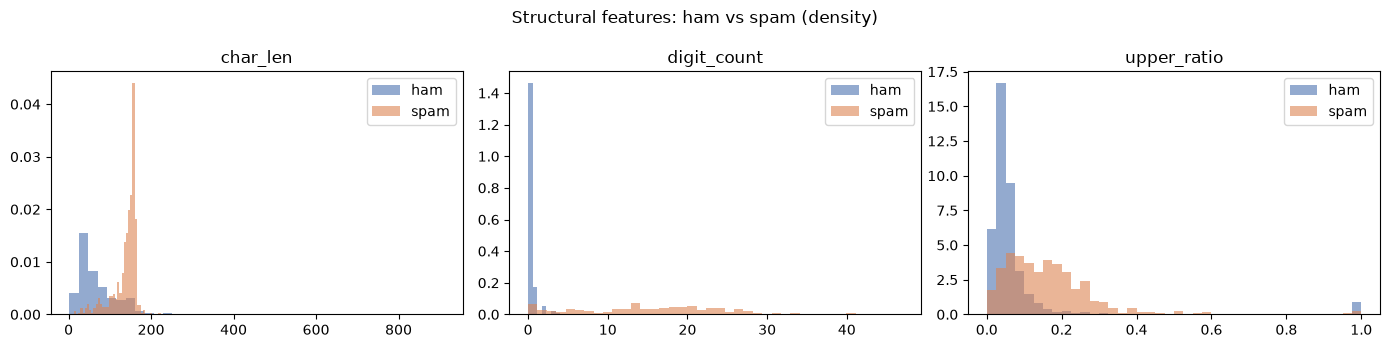

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.5))
for ax, col in zip(axes, ["char_len", "digit_count", "upper_ratio"]):
    for label, color in [("ham", "#4C72B0"), ("spam", "#DD8452")]:
        ax.hist(df.loc[df["label"] == label, col], bins=40, alpha=0.6, label=label,
                color=color, density=True)
    ax.set_title(col)
    ax.legend()
plt.suptitle("Structural features: ham vs spam (density)")
plt.tight_layout()
plt.show()

### Train / test split (stratified 80/20)

In [9]:
X = df[["clean"] + STRUCT_COLS]
y = df["target"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
print("Train:", X_train.shape, f"spam={y_train.mean():.1%}")
print("Test: ", X_test.shape, f"spam={y_test.mean():.1%}")

Train: (4136, 8) spam=12.6%
Test:  (1035, 8) spam=12.7%


In [10]:
def text_only(vectorizer):
    return ColumnTransformer([("text", vectorizer, "clean")])

def text_plus_struct(vectorizer):
    return ColumnTransformer([
        ("text", vectorizer, "clean"),
        ("struct", MaxAbsScaler(), STRUCT_COLS),
    ])

def tfidf():
    return TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True, stop_words="english")

def counts():
    return CountVectorizer(ngram_range=(1, 2), min_df=2, stop_words="english")

demo = text_plus_struct(tfidf()).fit(X_train)
print("Feature matrix shape (TF-IDF + structural):", demo.transform(X_train).shape)

Feature matrix shape (TF-IDF + structural): (4136, 5694)


## 4. Model training

Hyperparameters are tuned with 5-fold stratified CV on the training set only, scoring = spam-class F1.

| Name | Features | Model |
|------|----------|-------|
| NB (baseline) | word counts (1–2 grams) | Multinomial Naive Bayes |
| LogReg (text only) | TF-IDF (1–2 grams) | Logistic Regression, balanced |
| LogReg (text + struct) | TF-IDF + structural | Logistic Regression, balanced |
| LinearSVM (text + struct) | TF-IDF + structural | Linear SVM, balanced |

In [11]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

experiments = {
    "NB (baseline)": (
        Pipeline([("features", text_only(counts())), ("clf", MultinomialNB())]),
        {"clf__alpha": [0.1, 0.3, 1.0, 2.0, 3.0]}),
    "LogReg (text only)": (
        Pipeline([("features", text_only(tfidf())),
                  ("clf", LogisticRegression(class_weight="balanced", max_iter=2000))]),
        {"clf__C": [3, 10, 30, 100, 300, 1000]}),
    "LogReg (text + struct)": (
        Pipeline([("features", text_plus_struct(tfidf())),
                  ("clf", LogisticRegression(class_weight="balanced", max_iter=2000))]),
        {"clf__C": [3, 10, 30, 100, 300, 1000]}),
    "LinearSVM (text + struct)": (
        Pipeline([("features", text_plus_struct(tfidf())),
                  ("clf", LinearSVC(class_weight="balanced"))]),
        {"clf__C": [0.1, 0.3, 1, 3, 10]}),
}

fitted = {}
for name, (pipe, grid) in experiments.items():
    search = GridSearchCV(pipe, grid, scoring="f1", cv=cv, n_jobs=-1)
    search.fit(X_train, y_train)
    fitted[name] = search.best_estimator_
    print(f"{name:28s} best={search.best_params_}  CV F1={search.best_score_:.4f}")

NB (baseline)                best={'clf__alpha': 2.0}  CV F1=0.9479


LogReg (text only)           best={'clf__C': 100}  CV F1=0.9498


LogReg (text + struct)       best={'clf__C': 1000}  CV F1=0.9467


LinearSVM (text + struct)    best={'clf__C': 1}  CV F1=0.9435


## 5. Evaluation on the held-out test set

In [12]:
def scores(model, X, y):
    pred = model.predict(X)
    clf = model.named_steps["clf"]
    score = model.decision_function(X) if hasattr(clf, "decision_function") else model.predict_proba(X)[:, 1]
    return {
        "F1 (spam)": f1_score(y, pred),
        "Precision (spam)": precision_score(y, pred),
        "Recall (spam)": recall_score(y, pred),
        "MCC": matthews_corrcoef(y, pred),
        "ROC-AUC": roc_auc_score(y, score),
        "Accuracy": accuracy_score(y, pred),
        "FP (ham→spam)": int(((pred == 1) & (y == 0)).sum()),
        "FN (spam→ham)": int(((pred == 0) & (y == 1)).sum()),
    }

results = pd.DataFrame({name: scores(m, X_test, y_test) for name, m in fitted.items()}).T
results[["FP (ham→spam)", "FN (spam→ham)"]] = results[["FP (ham→spam)", "FN (spam→ham)"]].astype(int)
results.sort_values("F1 (spam)", ascending=False).round(4)

,F1 (spam),Precision (spam),Recall (spam),MCC,ROC-AUC,Accuracy,FP (ham→spam),FN (spam→ham)
NB (baseline),0.9692,0.9767,0.9618,0.9648,0.9859,0.9923,3,5
LinearSVM (text + struct),0.9609,0.9840,0.9389,0.9558,0.9983,0.9903,2,8
LogReg (text + struct),0.9565,0.9918,0.9237,0.9513,0.9977,0.9894,1,10
LogReg (text only),0.9535,0.9685,0.9389,0.9470,0.9978,0.9884,4,8


In [13]:
print(f"Majority-class (always ham) accuracy for reference: {1 - y_test.mean():.4f}")

Majority-class (always ham) accuracy for reference: 0.8734


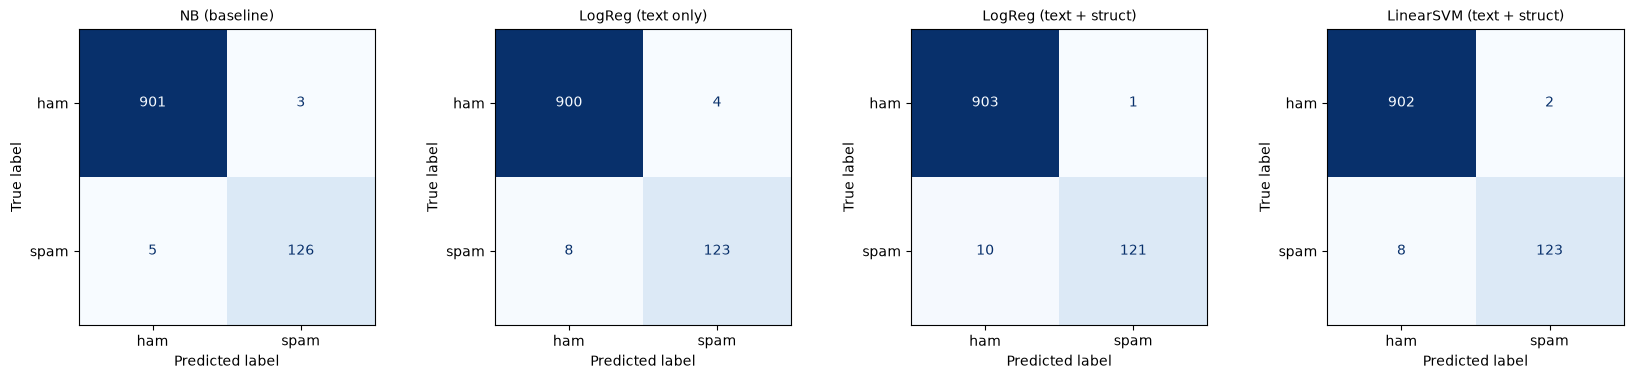

In [14]:
fig, axes = plt.subplots(1, len(fitted), figsize=(4.2 * len(fitted), 3.8))
for ax, (name, model) in zip(axes, fitted.items()):
    ConfusionMatrixDisplay.from_estimator(model, X_test, y_test, display_labels=["ham", "spam"],
                                          cmap="Blues", colorbar=False, ax=ax)
    ax.set_title(name, fontsize=10)
plt.tight_layout()
plt.show()

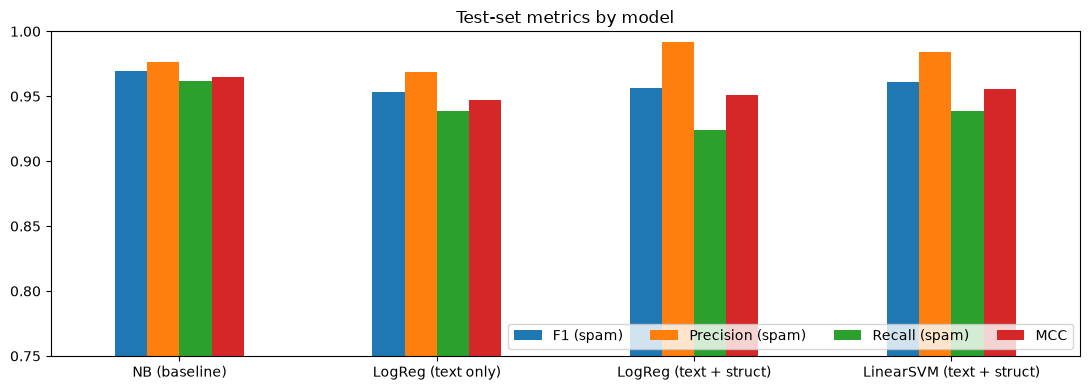

In [15]:
metric_cols = ["F1 (spam)", "Precision (spam)", "Recall (spam)", "MCC"]
results[metric_cols].plot.bar(figsize=(11, 4), ylim=(0.75, 1.0), rot=0)
plt.title("Test-set metrics by model")
plt.legend(loc="lower right", ncol=4)
plt.tight_layout()
plt.show()

In [16]:
best_name = results["F1 (spam)"].idxmax()
print("Best model by test F1:", best_name)
print(classification_report(y_test, fitted[best_name].predict(X_test), target_names=["ham", "spam"], digits=4))

Best model by test F1: NB (baseline)
              precision    recall  f1-score   support

         ham     0.9945    0.9967    0.9956       904
        spam     0.9767    0.9618    0.9692       131

    accuracy                         0.9923      1035
   macro avg     0.9856    0.9793    0.9824      1035
weighted avg     0.9922    0.9923    0.9922      1035



### Which tokens drive the predictions? (Logistic Regression, text + struct)

In [17]:
lr = fitted["LogReg (text + struct)"]
names = lr.named_steps["features"].get_feature_names_out()
coefs = pd.Series(lr.named_steps["clf"].coef_[0], index=names)
top_spam, top_ham = coefs.nlargest(15), coefs.nsmallest(15)
pd.DataFrame({
    "top spam features": top_spam.index.str.replace(r"^\w+?__", "", regex=True),
    "spam weight": top_spam.values.round(2),
    "top ham features": top_ham.index.str.replace(r"^\w+?__", "", regex=True),
    "ham weight": top_ham.values.round(2),
})

,top spam features,spam weight,top ham features,ham weight
0,digit_count,41.58,lt,-11.17
1,reply,16.58,gt,-11.17
2,phonetoken,16.43,lt gt,-10.75
3,arsenal,14.34,got,-7.75
4,mobile,14.28,hey,-6.75
5,brought,13.17,know,-6.13
6,service,11.96,numtoken numtoken,-5.96
7,sale,11.11,home,-5.51
8,rgds,11.10,missing,-5.45
9,enjoy,11.03,ring ur,-5.22


In [18]:
print("Structural feature weights (positive = pushes towards spam):")
coefs[[f"struct__{c}" for c in STRUCT_COLS]].round(3)

Structural feature weights (positive = pushes towards spam):


struct__char_len          7.175
struct__word_count        0.673
struct__digit_count      41.580
struct__upper_ratio       1.092
struct__has_url          10.443
struct__has_currency      3.861
struct__exclaim_count     5.865
dtype: float64

### Error analysis — misclassified test messages (best model)

In [19]:
best = fitted[best_name]
test_view = df.loc[X_test.index, ["label", "message"]].copy()
test_view["pred"] = np.where(best.predict(X_test) == 1, "spam", "ham")
errors = test_view[test_view["label"] != test_view["pred"]]
print(f"{len(errors)} errors out of {len(test_view)} test messages")
errors

8 errors out of 1035 test messages


,label,message,pred
4499,spam,Check Out Choose Your Babe Videos @ sms.shsex.netUN fgkslpoPW fgkslpo,ham
4538,ham,Nokia phone is lovly..,spam
3332,spam,"Xmas & New Years Eve tickets are now on sale from the club, during the day from 10am till 8pm, and on Thurs, Fri & S...",ham
1813,spam,Would you like to see my XXX pics they are so hot they were nearly banned in the uk!,ham
2303,spam,Babe: U want me dont u baby! Im nasty and have a thing 4 filthyguys. Fancy a rude time with a sexy bitch. How about ...,ham
4299,ham,Have you laid your airtel line to rest?,spam
3890,spam,"In The Simpsons Movie released in July 2007 name the band that died at the start of the film? A-Green Day, B-Blue Da...",ham
2890,ham,Your bill at 3 is £33.65 so thats not bad!,spam
